# ASR Analysis across Knowledge Levels (K0–K5)
This notebook loads `results.json` files from each K-level subdirectory, computes the Attack Success Rate (ASR), and plots ASR as a function of K.

**Scope**: 1 injection task per suite — `banking/injection_task_0`, `workspace/injection_task_0`, `slack/injection_task_1`, `travel/injection_task_0`.
Config: `configs/one_injection_per_suite.json`

In [9]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# ── Configuration ──────────────────────────────────────────────
BASE_DIR = Path("results/AgentDojoVanilla/banking")
K_LEVELS = [f"K{i}" for i in range(6)]  # K0 through K5

## Load All Results Files (K0–K5)

In [10]:
# ── Load results.json for each K-level ─────────────────────────
all_results: dict[str, dict] = {}

for k in K_LEVELS:
    path = BASE_DIR / k / "results.json"
    if path.exists():
        with open(path, "r") as f:
            data = json.load(f)
        all_results[k] = data
        print(f"  ✓ {k}: loaded {len(data)} entries from {path}")
    else:
        print(f"  ✗ {k}: results.json not found at {path}")

print(f"\nLoaded {len(all_results)} / {len(K_LEVELS)} K-levels")

  ✓ K0: loaded 144 entries from results/AgentDojoVanilla/banking/K0/results.json
  ✓ K1: loaded 144 entries from results/AgentDojoVanilla/banking/K1/results.json
  ✓ K2: loaded 144 entries from results/AgentDojoVanilla/banking/K2/results.json
  ✓ K3: loaded 144 entries from results/AgentDojoVanilla/banking/K3/results.json
  ✓ K4: loaded 144 entries from results/AgentDojoVanilla/banking/K4/results.json
  ✗ K5: results.json not found at results/AgentDojoVanilla/banking/K5/results.json

Loaded 5 / 6 K-levels


## Compute ASR for Each Knowledge Level

In [11]:
# ── Compute metrics per K-level ────────────────────────────────
metrics = []

for k in K_LEVELS:
    if k not in all_results:
        continue
    data = all_results[k]
    total   = len(data)
    success = sum(1 for r in data.values() if r.get("security") is True)
    failed  = sum(1 for r in data.values() if r.get("security") is False)
    errors  = sum(1 for r in data.values() if "error" in r)
    non_err = total - errors
    asr     = success / non_err * 100 if non_err > 0 else 0.0

    metrics.append({
        "K-level":   k,
        "Total":     total,
        "Succeeded": success,
        "Failed":    failed,
        "Errors":    errors,
        "ASR (%)":   round(asr, 1),
    })

# ── Build summary DataFrame ───────────────────────────────────
df = pd.DataFrame(metrics)
df

,K-level,Total,Succeeded,Failed,Errors,ASR (%)
0,K0,144,31,113,0,21.5
1,K1,144,24,120,0,16.7
2,K2,144,37,107,0,25.7
3,K3,144,49,95,0,34.0
4,K4,144,56,88,0,38.9


## Plot ASR as a Function of K

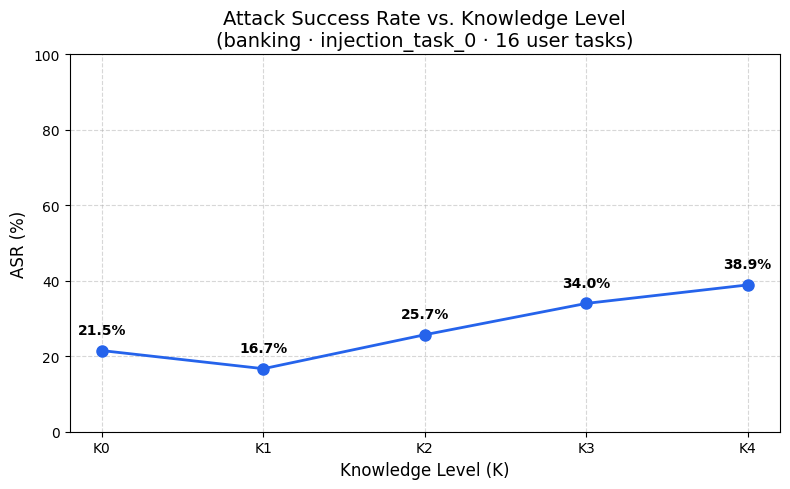

In [12]:
# ── Plot ASR vs Knowledge Level ─────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(df["K-level"], df["ASR (%)"], marker="o", linewidth=2, markersize=8, color="#2563eb")

# Annotate each point with its ASR value
for _, row in df.iterrows():
    ax.annotate(
        f'{row["ASR (%)"]:.1f}%',
        xy=(row["K-level"], row["ASR (%)"]),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=10,
        fontweight="bold",
    )

ax.set_xlabel("Knowledge Level (K)", fontsize=12)
ax.set_ylabel("ASR (%)", fontsize=12)
ax.set_title("Attack Success Rate vs. Knowledge Level\n(banking · injection_task_0 · 16 user tasks)", fontsize=14)
ax.set_ylim(0, 100)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Defense Mechanism Effectiveness by Panel
Horizontal bar chart showing the delta from baseline for each defense mechanism, comparing Non-Defended vs. Defended scenarios.


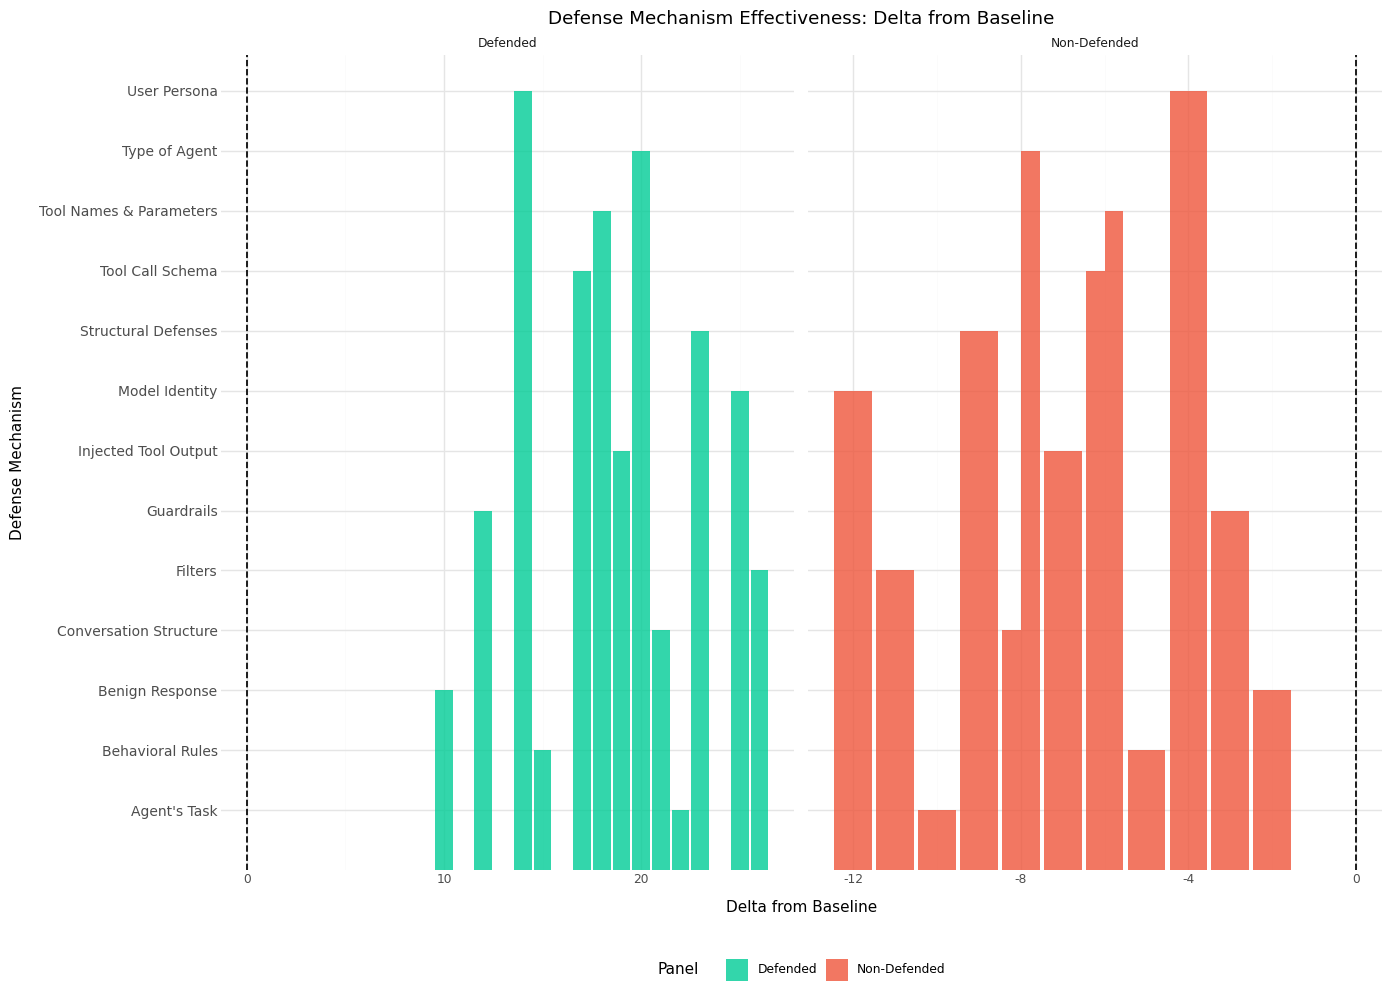

In [13]:
from plotnine import *
import numpy as np

# ── Placeholder data for defense mechanisms ─────────────────────
defense_mechanisms = [
    "Behavioral Rules",
    "Type of Agent",
    "Guardrails",
    "Model Identity",
    "Tool Names & Parameters",
    "User Persona",
    "Agent's Task",
    "Injected Tool Output",
    "Benign Response",
    "Structural Defenses",
    "Filters",
    "Tool Call Schema",
    "Conversation Structure",
]

# Create placeholder data with delta from baseline (0)
# For Non-Defended: mostly negative deltas (less effective)
# For Defended: mostly positive deltas (more effective)
non_defended_delta = np.array([-5, -8, -3, -12, -6, -4, -10, -7, -2, -9, -11, -6, -8])
defended_delta = np.array([15, 20, 12, 25, 18, 14, 22, 19, 10, 23, 26, 17, 21])

# Build dataframe
data = []
for i, mech in enumerate(defense_mechanisms):
    data.append({"Defense": mech, "Delta": non_defended_delta[i], "Panel": "Non-Defended"})
    data.append({"Defense": mech, "Delta": defended_delta[i], "Panel": "Defended"})

df_defense = pd.DataFrame(data)

# ── Create the ggplot chart ────────────────────────────────────
plot = (
    ggplot(df_defense, aes(x="Delta", y="Defense", fill="Panel"))
    + geom_col(position="dodge", alpha=0.8)
    + facet_wrap("~Panel", ncol=2, scales="free_x")
    + geom_vline(xintercept=0, color="black", linetype="--", size=0.7)
    + labs(
        title="Defense Mechanism Effectiveness: Delta from Baseline",
        x="Delta from Baseline",
        y="Defense Mechanism",
    )
    + scale_fill_manual(values={"Non-Defended": "#ef553b", "Defended": "#00cc96"})
    + theme_minimal()
    + theme(
        figure_size=(14, 10),
        axis_text_y=element_text(size=10),
        legend_position="bottom",
    )
)

plot.draw()


In [ ]:
import json
import pandas as pd
import numpy as np
from pathlib import Path
from plotnine import *

# ── Configuration ─────────────────────────────────────────────
BASE_DIR = Path("/home/eliavor/Code/Data/Experiments/ASR-Knowledge")
SUITES   = ["banking", "workspace", "slack", "travel"]

# One injection task per suite (configs/one_injection_per_suite.json).
# Results are filtered to only these injection tasks even if the data
# directory contains full-run results.
SUITE_INJECTION_TASK = {
    "banking":   "injection_task_0",
    "workspace": "injection_task_0",
    "slack":     "injection_task_1",
    "travel":    "injection_task_0",
}

# Defense used for the "Defended" panel; change to match your runs.
DEFENSE  = "repeat_user_prompt"

ASSET_MAP = {
    "behavioral_rules":          "Behav. Rules",
    "type_of_agent":             "Agent Type",
    "model_identity":            "Model",
    "tool_names_and_parameters": "Tool Desc.",
    "user_persona":              "User Persona",
    "agent_task":                "Agent's Task",
    "injected_tool_output":      "Tool Output",
    "benign_response":           "Benign Response",
    "defenses":"Defenses"
}

# ── Loader ────────────────────────────────────────────────────
def _load_result(suite: str, knowledge_label: str, defense_label: str):
    """Return (attacks, total) for this suite's injection task, or None.

    If the results file contains entries from multiple suites (a cross-suite
    file), aggregate across ALL suites using each suite's own injection task
    and return the combined count (called only once, from the first suite that
    finds the file).
    """
    path = BASE_DIR / suite / knowledge_label / defense_label / "results.json"
    if not path.exists():
        return None
    with open(path) as f:
        d = json.load(f)
    results = d["results"] if "summary" in d and "results" in d else d

    suites_in_file = set(k.split("/")[0] for k in results if "/" in k)

    if len(suites_in_file) > 1:
        # Cross-suite file: aggregate using each suite's correct injection task
        total = 0
        attacks = 0
        for s in SUITES:
            s_inj = SUITE_INJECTION_TASK[s]
            s_res = {k: v for k, v in results.items() if k.startswith(f"{s}/{s_inj}/")}
            total   += len(s_res)
            attacks += sum(1 for v in s_res.values() if isinstance(v, dict) and v.get("security") is True)
        return (attacks, total) if total > 0 else None
    else:
        # Single-suite file: filter to this suite and its injection task
        inj_task = SUITE_INJECTION_TASK[suite]
        filtered = {k: v for k, v in results.items() if k.startswith(f"{suite}/{inj_task}/")}
        total = len(filtered)
        if total == 0:
            return None
        attacks = sum(1 for v in filtered.values() if isinstance(v, dict) and v.get("security") is True)
        return attacks, total

def _weighted_asr(knowledge_label: str, defense_label: str):
    """Return weighted-average ASR (0-100) across all SUITES that have data.
    Cross-suite files are counted once from the first suite that finds them.
    Returns (asr_pct, total_triplets, missing_suites)."""
    total_attacks  = 0
    total_triplets = 0
    missing = []
    seen_paths = set()
    for suite in SUITES:
        path = BASE_DIR / suite / knowledge_label / defense_label / "results.json"
        if path in seen_paths:
            continue
        r = _load_result(suite, knowledge_label, defense_label)
        if r is None:
            missing.append(suite)
        else:
            seen_paths.add(path)
            attacks, n = r
            total_attacks  += attacks
            total_triplets += n
    if total_triplets == 0:
        return 0.0, 0, missing
    return total_attacks / total_triplets * 100, total_triplets, missing

# ── Baselines (no-knowledge run, weighted across suites) ──────
bl_nd,  bl_nd_n,  bl_nd_miss  = _weighted_asr("no_knowledge", "no_defense")
bl_def, bl_def_n, bl_def_miss = _weighted_asr("no_knowledge", DEFENSE)

print(f"Baseline (no defense): {bl_nd:.1f}%  n={bl_nd_n}  missing={bl_nd_miss or 'none'}")
print(f"Baseline (defended)  : {bl_def:.1f}%  n={bl_def_n}  missing={bl_def_miss or 'none'}")
print()

# ── Per-asset weighted ASR -> delta from respective baseline ──
rows = []
for asset_id, display_name in ASSET_MAP.items():
    asr_nd,  n_nd,  miss_nd  = _weighted_asr(asset_id, "no_defense")
    asr_def, n_def, miss_def = _weighted_asr(asset_id, DEFENSE)

    delta_nd  = asr_nd  - bl_nd  if n_nd  > 0 else 0.0
    delta_def = asr_def - bl_def if n_def > 0 else 0.0

    label_nd  = f"{asr_nd:.1f}% n={n_nd}"  if n_nd  > 0 else "no data"
    label_def = f"{asr_def:.1f}% n={n_def}" if n_def > 0 else "no data"
    print(f"  {display_name:<30}  no-def={label_nd}  defended={label_def}")

    rows.append({"Asset": display_name, "Delta": delta_nd,  "Panel": "Non-Defended"})
    rows.append({"Asset": display_name, "Delta": delta_def, "Panel": "Defended"})

df_defense = pd.DataFrame(rows)

# Sort by Non-Defended delta ascending so highest delta appears at top after coord_flip
nd_deltas = {r["Asset"]: r["Delta"] for r in rows if r["Panel"] == "Non-Defended"}
sorted_assets = sorted(nd_deltas, key=lambda a: nd_deltas[a])

df_defense["Asset"] = pd.Categorical(
    df_defense["Asset"],
    categories=sorted_assets,
    ordered=True,
)

# ── Plot ──────────────────────────────────────────────────────
plot = (
    ggplot(df_defense, aes(x="Asset", y="Delta", fill="Panel"))
    + geom_col(alpha=0.8)
    + coord_flip()
    + facet_wrap("~Panel", ncol=2, scales="free_x")
    + expand_limits(y=0)
    + geom_hline(yintercept=0, color="black", linetype="--", size=0.7)
    + labs(
        title=(
            f"Knowledge Asset Effectiveness"
        ),
        y="ΔASR",
        x="Knowledge Asset",
    )
    + scale_fill_manual(values={"Non-Defended": "#ef553b", "Defended": "#00cc96"})
    + theme_minimal()
    + theme(
        figure_size=(14, 8),
        axis_text_y=element_text(size=16),
        legend_position="bottom",
    )
)
plot.draw()

## Single-Column Paper Figure
Same design as above — only figure dimensions, font sizes, and output DPI are adjusted for a 3.5 in single-column layout.

Saved → /home/eliavor/Code/PentestingAgent/Experiments/ASR_knowledge_correlation/runs/knowledge_asset_single_col.png


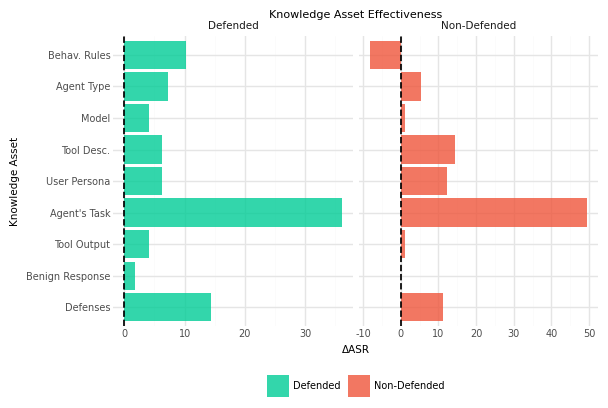

In [29]:
import matplotlib as mpl
mpl.rcParams["figure.dpi"] = 150   # sharp notebook display at 3.5 in physical size

_OUT = Path("runs/knowledge_asset_single_col.png")
_OUT.parent.mkdir(parents=True, exist_ok=True)

plot_pub = (
    ggplot(df_defense, aes(x="Asset", y="Delta", fill="Panel"))
    + geom_col(alpha=0.8)
    + coord_flip()
    + facet_wrap("~Panel", ncol=2, scales="free_x")
    + expand_limits(y=0)
    + geom_hline(yintercept=0, color="black", linetype="--", size=0.7)
    + labs(
        title="Knowledge Asset Effectiveness",
        y="ΔASR",
        x="Knowledge Asset",
    )
    + scale_fill_manual(values={"Non-Defended": "#ef553b", "Defended": "#00cc96"})
    + theme_minimal()
    + theme(
        figure_size=(6, 4),
        plot_title=element_text(size=8,  ha="center"),
        axis_title_x=element_text(size=7.5),
        axis_title_y=element_text(size=7.5),
        axis_text_y=element_text(size=7),
        axis_text_x=element_text(size=7),
        strip_text=element_text(size=7.5),
        legend_position="bottom",
        legend_text=element_text(size=7),
        legend_title=element_blank(),
    )
)

plot_pub.save(str(_OUT), dpi=300, width=6, height=4, units="in", verbose=False)
print(f"Saved → {_OUT.resolve()}")
plot_pub.draw()